# Olist E-Commerce Customer Retention Analysis

## 1. Customer Retention, Cohort Analysis & RFM Segmentation

### Objective
This notebook investigates repeat purchasing behavior, measures monthly customer cohort retention, and segments customers by recency, frequency, and monetary value.

### Business Questions
1. What proportion of customers place more than one delivered order?
2. How does customer activity change after the month of a customer's first delivered purchase?
3. Which customer groups are recent, frequent, or high-spending?
4. Which segments could be prioritized for retention or reactivation campaigns?

### Methodology
- Use delivered orders for the core purchase analysis.
- Identify customers using `customer_unique_id`, not the order-level `customer_id`.
- Define each cohort by the calendar month of the customer's first delivered purchase.
- Calculate retention as the percentage of cohort customers with at least one delivered order in each subsequent calendar month.
- Calculate RFM values using the latest purchase date in the delivered-order dataset as the reference date.
- Treat campaign recommendations as hypotheses to test, not proven outcomes.

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, and the Olist CSV datasets.


## 2. Load and Prepare Data

This section loads the orders, customer mapping, and order-item tables. Paths are relative to the project root so the notebook can be run on another machine when the project structure is preserved.


In [10]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"
PROCESSED_DATA.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(RAW_DATA / "olist_orders_dataset.csv")
customers = pd.read_csv(RAW_DATA / "olist_customers_dataset.csv")
order_items = pd.read_csv(RAW_DATA / "olist_order_items_dataset.csv")

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order items:", order_items.shape)


Orders: (99441, 8)
Customers: (99441, 5)
Order items: (112650, 7)


## 3. Build the Delivered-Order Customer Dataset

Only orders with `order_status == "delivered"` are included in the core retention analysis. The customer mapping supplies `customer_unique_id`, which connects multiple customer records belonging to the same underlying customer.


In [11]:
delivered = orders.loc[
    orders["order_status"].eq("delivered"),
    ["order_id", "customer_id", "order_purchase_timestamp",
     "order_delivered_customer_date"]
].copy()

delivered = delivered.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

delivered = delivered.dropna(
    subset=["order_id", "customer_unique_id", "order_purchase_timestamp"]
)

delivered["order_month"] = (
    delivered["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
)

print(f"Delivered orders: {delivered['order_id'].nunique():,}")
print(f"Unique purchasing customers: {delivered['customer_unique_id'].nunique():,}")
display(delivered.head())


Delivered orders: 96,478
Unique purchasing customers: 93,358


,order_id,customer_id,order_purchase_timestamp,order_delivered_customer_date,customer_unique_id,order_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-10 21:25:13,7c396fd4830fd04220f754e42b4e5bff,2017-10-01
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-07 15:27:45,af07308b275d755c9edb36a90c618231,2018-07-01
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-17 18:06:29,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-01
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-02 00:28:42,7c142cf63193a1473d2e66489a9ae977,2017-11-01
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-16 18:17:02,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-01


## 4. Repeat Purchase Analysis

A repeat customer is defined as a unique customer with at least two distinct delivered orders. A one-time customer has exactly one delivered order in the available dataset.


In [12]:
customer_frequency = (
    delivered.groupby("customer_unique_id")["order_id"]
    .nunique()
    .rename("frequency")
    .reset_index()
)

total_customers = customer_frequency["customer_unique_id"].nunique()
one_time_customers = int(customer_frequency["frequency"].eq(1).sum())
repeat_customers = int(customer_frequency["frequency"].ge(2).sum())
repeat_rate = repeat_customers / total_customers if total_customers else 0

retention_summary = pd.DataFrame({
    "Metric": [
        "Delivered orders",
        "Unique purchasing customers",
        "One-time customers",
        "Repeat customers",
        "Repeat customer rate"
    ],
    "Value": [
        delivered["order_id"].nunique(),
        total_customers,
        one_time_customers,
        repeat_customers,
        round(repeat_rate * 100, 2)
    ]
})
display(retention_summary)
print(f"Repeat customer rate: {repeat_rate:.2%}")


,Metric,Value
0,Delivered orders,96478.0
1,Unique purchasing customers,93358.0
2,One-time customers,90557.0
3,Repeat customers,2801.0
4,Repeat customer rate,3.0


Repeat customer rate: 3.00%


,Delivered Orders,Customer Count
0,1,90557
1,2,2573
2,3,181
3,4,28
4,5,9
5,6,5
6,7,3
7,9,1
8,15,1


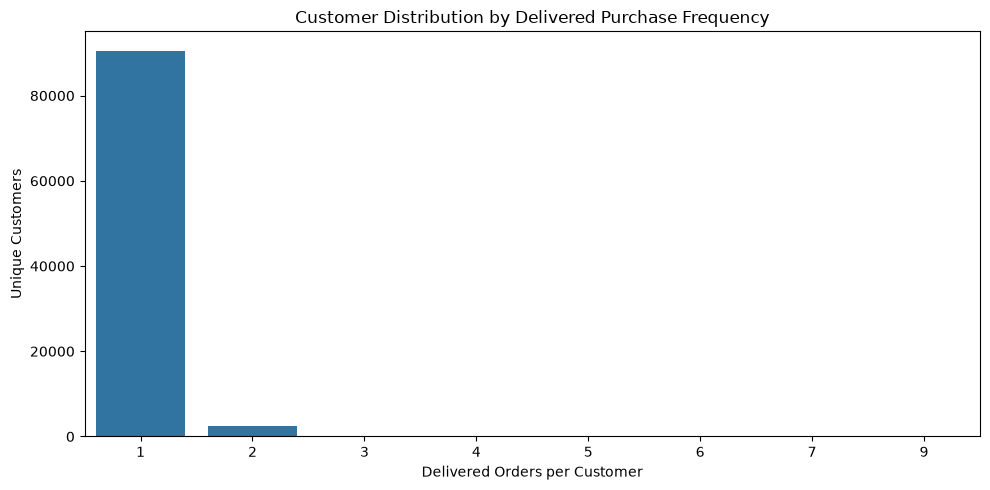

In [13]:
purchase_frequency_distribution = (
    customer_frequency["frequency"]
    .value_counts()
    .sort_index()
    .rename_axis("Delivered Orders")
    .reset_index(name="Customer Count")
)

display(purchase_frequency_distribution.head(15))

plot_frequency = purchase_frequency_distribution[
    purchase_frequency_distribution["Delivered Orders"] <= 10
]
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_frequency, x="Delivered Orders", y="Customer Count")
plt.title("Customer Distribution by Delivered Purchase Frequency")
plt.xlabel("Delivered Orders per Customer")
plt.ylabel("Unique Customers")
plt.tight_layout()
plt.show()


## 5. Monthly Cohort Retention Analysis

Each customer is assigned to a cohort based on the month of their first delivered purchase. For each cohort, monthly retention is the number of cohort customers with at least one delivered order in the activity month divided by the cohort's customer count.

Month 0 represents the cohort's first delivered-purchase month and is expected to have 100% retention by definition.


**Heatmap presentation note:** Cohort labels are displayed as abbreviated month and year (for example, `Jan 2017`). The heatmap color scale is capped at 10% to make small retention differences easier to see; values above 10% use the darkest color. Month 0 remains 100% by definition. Blank cells indicate that a cohort has no observation for that follow-up month, not zero retention.


In [14]:
# First delivered-purchase month per customer
first_purchase = (
    delivered.groupby("customer_unique_id")["order_purchase_timestamp"]
    .min()
    .rename("first_purchase_date")
    .reset_index()
)

first_purchase["cohort_month"] = (
    first_purchase["first_purchase_date"].dt.to_period("M").dt.to_timestamp()
)

cohort_orders = delivered.merge(
    first_purchase[["customer_unique_id", "cohort_month"]],
    on="customer_unique_id",
    how="left",
    validate="many_to_one"
)

cohort_orders["activity_month"] = (
    cohort_orders["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
)

cohort_orders["cohort_index"] = (
    (cohort_orders["activity_month"].dt.year - cohort_orders["cohort_month"].dt.year) * 12
    + (cohort_orders["activity_month"].dt.month - cohort_orders["cohort_month"].dt.month)
)

cohort_counts = (
    cohort_orders.groupby(["cohort_month", "cohort_index"])["customer_unique_id"]
    .nunique()
    .reset_index(name="active_customers")
)

cohort_sizes = (
    first_purchase.groupby("cohort_month")["customer_unique_id"]
    .nunique()
    .rename("cohort_size")
    .reset_index()
)

cohort_retention = cohort_counts.merge(
    cohort_sizes, on="cohort_month", how="left", validate="many_to_one"
)
cohort_retention["retention_rate"] = (
    cohort_retention["active_customers"] / cohort_retention["cohort_size"]
)

display(cohort_retention.head(10))
print("Month 0 retention values:")
display(cohort_retention.loc[cohort_retention["cohort_index"].eq(0),
                             ["cohort_month", "cohort_size", "active_customers", "retention_rate"]].head())


,cohort_month,cohort_index,active_customers,cohort_size,retention_rate
0,2016-09-01,0,1,1,1.000000
1,2016-10-01,0,262,262,1.000000
2,2016-10-01,6,1,262,0.003817
3,2016-10-01,9,1,262,0.003817
4,2016-10-01,11,1,262,0.003817
5,2016-10-01,13,1,262,0.003817
6,2016-10-01,15,1,262,0.003817
7,2016-10-01,17,1,262,0.003817
8,2016-10-01,19,2,262,0.007634
9,2016-10-01,20,2,262,0.007634


Month 0 retention values:


,cohort_month,cohort_size,active_customers,retention_rate
0,2016-09-01,1,1,1.0
1,2016-10-01,262,262,1.0
10,2016-12-01,1,1,1.0
12,2017-01-01,717,717,1.0
30,2017-02-01,1628,1628,1.0


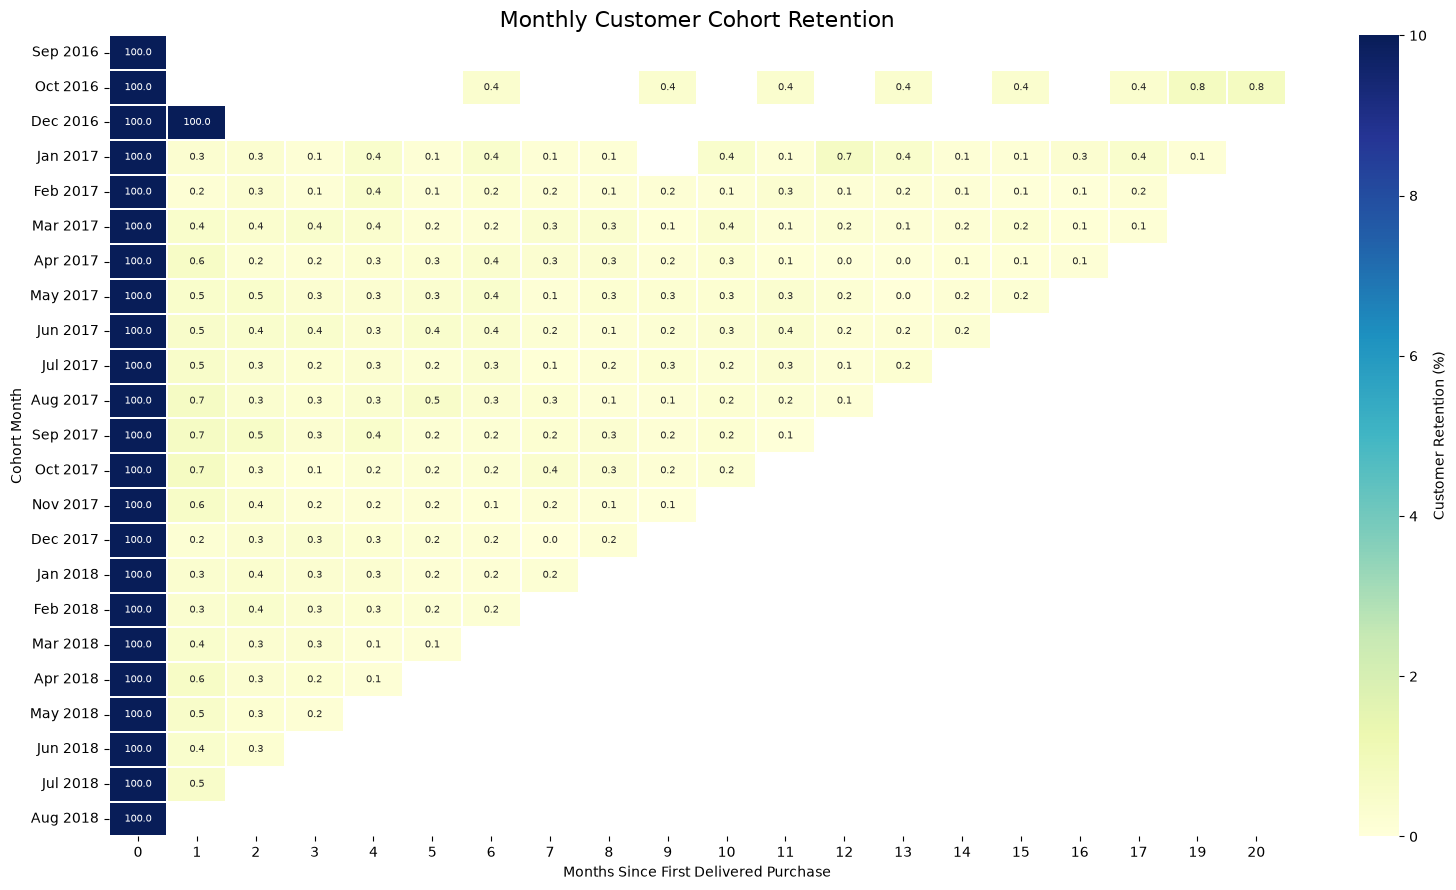

In [15]:
# Create a display copy so the original cohort month index remains available for analysis
cohort_pivot = (
    cohort_retention
    .pivot(
        index="cohort_month",
        columns="cohort_index",
        values="retention_rate"
    )
    .sort_index()
)

cohort_pivot.columns.name = None
cohort_display = cohort_pivot.copy()
cohort_display.index = pd.to_datetime(cohort_display.index).strftime("%b %Y")

plt.figure(figsize=(16, 9))
sns.heatmap(
    cohort_display * 100,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    annot_kws={"size": 7},
    linewidths=0.25,
    vmin=0,
    vmax=10,
    cbar_kws={"label": "Customer Retention (%)"}
)
plt.title("Monthly Customer Cohort Retention", fontsize=16)
plt.xlabel("Months Since First Delivered Purchase")
plt.ylabel("Cohort Month")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [16]:
# Export cohort results for SQL / Power BI reuse
cohort_retention_export = cohort_retention.copy()
cohort_retention_export["cohort_month"] = cohort_retention_export["cohort_month"].dt.strftime("%Y-%m-%d")

cohort_retention_export.to_csv(
    PROCESSED_DATA / "python_cohort_retention.csv",
    index=False
)

cohort_sizes_export = cohort_sizes.copy()
cohort_sizes_export["cohort_month"] = cohort_sizes_export["cohort_month"].dt.strftime("%Y-%m-%d")
cohort_sizes_export.to_csv(
    PROCESSED_DATA / "python_cohort_sizes.csv",
    index=False
)

print("Saved cohort outputs to:", PROCESSED_DATA)


Saved cohort outputs to: c:\Users\dashp\OneDrive\Desktop\ecommerce-customer-retention\data\processed


## 6. RFM Customer Segmentation

RFM measures three aspects of customer behavior:

- **Recency:** Days since the customer's most recent delivered purchase.
- **Frequency:** Number of distinct delivered orders.
- **Monetary:** Sum of item prices across delivered orders, excluding freight/shipping.

The reference date is one day after the latest delivered purchase timestamp. Monetary values are in Brazilian Real (BRL) as represented by the source dataset. RFM scores use quintiles; the score direction is reversed for recency so a more recent customer receives a higher R score.


In [17]:
# Recency and frequency from delivered orders
reference_date = delivered["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

rf = (
    delivered.groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique")
    )
    .reset_index()
)
rf["recency"] = (reference_date - rf["last_purchase"].dt.normalize()).dt.days

# Aggregate item prices by order before joining, avoiding row multiplication
delivered_order_ids = delivered[["order_id", "customer_unique_id"]].drop_duplicates()
item_value_by_order = (
    order_items.groupby("order_id", as_index=False)
    .agg(order_item_value=("price", "sum"))
)

customer_monetary = delivered_order_ids.merge(
    item_value_by_order, on="order_id", how="left", validate="one_to_one"
)
customer_monetary = (
    customer_monetary.groupby("customer_unique_id")["order_item_value"]
    .sum(min_count=1)
    .rename("monetary")
    .reset_index()
)

rfm = rf.merge(
    customer_monetary, on="customer_unique_id", how="left", validate="one_to_one"
)
rfm["monetary"] = rfm["monetary"].fillna(0)

print("RFM customers:", rfm["customer_unique_id"].nunique())
display(rfm.head())
display(rfm[["recency", "frequency", "monetary"]].describe().round(2))


RFM customers: 93358


,customer_unique_id,last_purchase,frequency,recency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,112,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,115,18.90
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,538,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,322,25.99
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,289,180.00


,recency,frequency,monetary
count,93358.00,93358.00,93358.00
mean,238.48,1.03,141.62
std,152.60,0.21,215.69
min,1.00,1.00,0.85
25%,115.00,1.00,47.65
50%,219.00,1.00,89.73
75%,347.00,1.00,154.74
max,714.00,15.00,13440.00


In [18]:
# Quintile scoring. Rank first to handle tied values robustly.
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

def assign_segment(row):
    if row["frequency"] >= 2 and row["R_score"] >= 4:
        return "Recent Repeat Customers"
    elif row["frequency"] >= 2 and row["M_score"] >= 4:
        return "Repeat High-Value Customers"
    elif row["frequency"] >= 2:
        return "Other Repeat Customers"
    elif row["R_score"] >= 4 and row["M_score"] >= 4:
        return "Recent High-Value One-Time Customers"
    elif row["R_score"] <= 2:
        return "Lapsed One-Time Customers"
    elif row["M_score"] >= 4:
        return "High-Spend One-Time Customers"
    else:
        return "Other One-Time Customers"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("segment", as_index=False)
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_item_value=("monetary", "sum"),
        average_frequency=("frequency", "mean"),
        average_recency_days=("recency", "mean")
    )
)
segment_summary["customer_share_pct"] = (
    segment_summary["customers"] / rfm["customer_unique_id"].nunique() * 100
).round(2)

segment_summary = segment_summary.sort_values("customers", ascending=False)
display(segment_summary)


,segment,customers,total_item_value,average_frequency,average_recency_days,customer_share_pct
1,Lapsed One-Time Customers,36347,5073897.42,1.000000,395.473079,38.93
2,Other One-Time Customers,32787,1819447.23,1.000000,134.326318,35.12
4,Recent High-Value One-Time Customers,14483,3869193.01,1.000000,92.230270,15.51
0,High-Spend One-Time Customers,6940,1730551.70,1.000000,220.639193,7.43
5,Recent Repeat Customers,1203,325603.02,2.152951,89.223608,1.29
6,Repeat High-Value Customers,1203,373801.56,2.094763,315.494597,1.29
3,Other Repeat Customers,395,29004.17,2.053165,333.192405,0.42


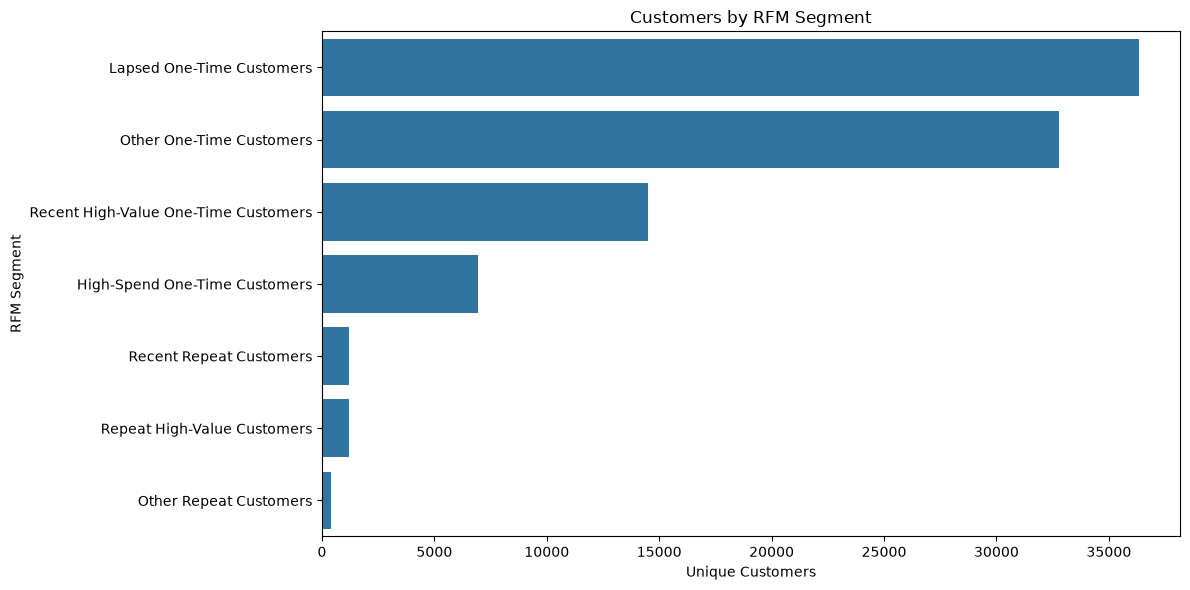

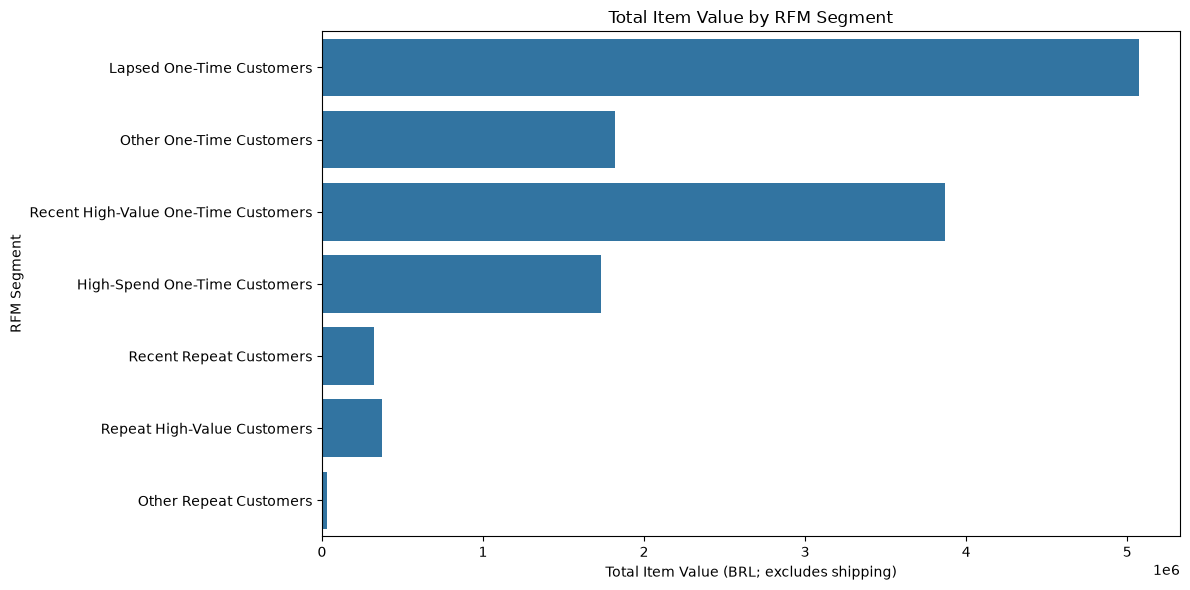

In [19]:
plt.figure(figsize=(12, 6))
sns.barplot(data=segment_summary, y="segment", x="customers")
plt.title("Customers by RFM Segment")
plt.xlabel("Unique Customers")
plt.ylabel("RFM Segment")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=segment_summary, y="segment", x="total_item_value")
plt.title("Total Item Value by RFM Segment")
plt.xlabel("Total Item Value (BRL; excludes shipping)")
plt.ylabel("RFM Segment")
plt.tight_layout()
plt.show()


In [20]:
# Export customer-level RFM and segment summary for Power BI / further analysis
rfm_export = rfm.copy()
rfm_export["last_purchase"] = rfm_export["last_purchase"].dt.strftime("%Y-%m-%d %H:%M:%S")
rfm_export.to_csv(PROCESSED_DATA / "python_rfm_customer_segments.csv", index=False)
segment_summary.to_csv(PROCESSED_DATA / "python_rfm_segment_summary.csv", index=False)

print("Saved:")
print(PROCESSED_DATA / "python_rfm_customer_segments.csv")
print(PROCESSED_DATA / "python_rfm_segment_summary.csv")


Saved:
c:\Users\dashp\OneDrive\Desktop\ecommerce-customer-retention\data\processed\python_rfm_customer_segments.csv
c:\Users\dashp\OneDrive\Desktop\ecommerce-customer-retention\data\processed\python_rfm_segment_summary.csv


## 7. Key Findings and Business Recommendations

### Interpretation Guide
- The repeat-customer rate is a baseline calculated from delivered orders in the available dataset.
- Cohort retention compares customer activity with the size of each customer's first-purchase cohort.
- Early cohort months have more observable follow-up months than recent cohorts. Blank cells in the retention heatmap mean no observation is available, not zero retention.
- RFM segments are rule-based groups that help prioritize analysis; they do not prove that a campaign will be effective.

### Recommended Actions to Test
1. Test relevant post-purchase reminders for one-time customers.
2. Offer personalized product recommendations based on previous purchases.
3. Consider loyalty benefits for repeat and high-value customers.
4. Test reactivation campaigns for customers whose last delivered purchase was a long time ago.
5. Compare repeat-purchase and cohort-retention metrics before and after campaigns.

### Limitations
- The dataset is historical and may not represent current customer behavior.
- Monetary value sums item prices and excludes freight/shipping.
- RFM segment labels depend on the chosen scoring and business rules.
- Campaign outcomes cannot be inferred from observational purchase data alone.

### Deliverables
This notebook produces cohort-retention CSVs and customer-level RFM outputs for comparison with the SQL analysis and Power BI dashboard.
